In [39]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

In [68]:
#느낀점 주석을 잘달아야할것같다

In [28]:
df = pd.read_csv(r'D:\wind\CARE_To_Compare\CARE_To_Compare\Wind Farm A\datasets\0.csv', sep=';')

In [5]:
df.head()

,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_1_avg,sensor_2_avg,wind_speed_3_avg,wind_speed_4_avg,...,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,sensor_52_avg,sensor_52_max,sensor_52_min,sensor_52_std,sensor_53_avg
0,2022-08-04 06:10:00,0,0,train,0,22.0,302.9,129.4,1.7,1.7,...,-496.0,0.0,0.0,-1280.0,-496.0,0.0,0.0,0.0,0.0,26.0
1,2022-08-04 06:20:00,0,1,train,0,22.0,307.1,133.6,1.7,1.7,...,-490.0,0.0,0.0,-1278.0,-490.0,0.0,0.0,0.0,0.0,25.0
2,2022-08-04 06:30:00,0,2,train,0,22.0,340.6,167.1,0.9,0.9,...,-490.0,0.0,0.0,-1356.0,-490.0,0.0,0.0,0.0,0.0,25.0
3,2022-08-04 06:40:00,0,3,train,0,22.0,124.4,-49.1,1.5,1.5,...,-509.0,0.0,0.0,-1274.0,-509.0,0.0,0.0,0.0,0.0,26.0
4,2022-08-04 06:50:00,0,4,train,0,22.0,66.2,-107.3,1.0,1.0,...,-499.0,0.0,0.0,-1284.0,-499.0,0.0,0.0,0.0,0.0,26.0


In [29]:
df.shape

(54986, 86)

In [30]:
df.isna().sum().sum()

np.int64(2)

In [31]:
df['time_stamp'].info() #str

<class 'pandas.Series'>
RangeIndex: 54986 entries, 0 to 54985
Series name: time_stamp
Non-Null Count  Dtype
--------------  -----
54986 non-null  str  
dtypes: str(1)
memory usage: 1.4 MB


In [32]:
df['time_stamp'] = pd.to_datetime(df['time_stamp'])

In [33]:
df['time_stamp'].info() # datetime64[us]

<class 'pandas.Series'>
RangeIndex: 54986 entries, 0 to 54985
Series name: time_stamp
Non-Null Count  Dtype         
--------------  -----         
54986 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 429.7 KB


In [34]:
df.set_index('time_stamp', inplace=True)

In [38]:
df.index.to_list()

[Timestamp('2022-08-04 06:10:00'),
 Timestamp('2022-08-04 06:20:00'),
 Timestamp('2022-08-04 06:30:00'),
 Timestamp('2022-08-04 06:40:00'),
 Timestamp('2022-08-04 06:50:00'),
 Timestamp('2022-08-04 07:00:00'),
 Timestamp('2022-08-04 07:10:00'),
 Timestamp('2022-08-04 07:20:00'),
 Timestamp('2022-08-04 07:30:00'),
 Timestamp('2022-08-04 07:40:00'),
 Timestamp('2022-08-04 07:50:00'),
 Timestamp('2022-08-04 08:00:00'),
 Timestamp('2022-08-04 08:10:00'),
 Timestamp('2022-08-04 08:20:00'),
 Timestamp('2022-08-04 08:30:00'),
 Timestamp('2022-08-04 08:40:00'),
 Timestamp('2022-08-04 08:50:00'),
 Timestamp('2022-08-04 09:00:00'),
 Timestamp('2022-08-04 09:10:00'),
 Timestamp('2022-08-04 09:20:00'),
 Timestamp('2022-08-04 09:30:00'),
 Timestamp('2022-08-04 09:40:00'),
 Timestamp('2022-08-04 09:50:00'),
 Timestamp('2022-08-04 10:00:00'),
 Timestamp('2022-08-04 10:10:00'),
 Timestamp('2022-08-04 10:20:00'),
 Timestamp('2022-08-04 10:30:00'),
 Timestamp('2022-08-04 10:40:00'),
 Timestamp('2022-08-

In [47]:
corr_matrix =df.corr(numeric_only=True) 
corr_matrix

,asset_id,id,status_type_id,sensor_0_avg,sensor_1_avg,sensor_2_avg,wind_speed_3_avg,wind_speed_4_avg,wind_speed_3_max,wind_speed_3_min,...,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,sensor_52_avg,sensor_52_max,sensor_52_min,sensor_52_std,sensor_53_avg
asset_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,NaN,1.000000,0.154801,0.151934,0.065292,-0.004101,0.001835,-0.005676,0.010736,-0.023894,...,-0.028178,-0.013471,NaN,0.023291,-0.015943,0.025636,0.035054,0.013309,0.036529,0.165234
status_type_id,NaN,0.154801,1.000000,0.410402,-0.074108,-0.009243,0.145099,0.131487,0.087980,0.172310,...,-0.109640,-0.017654,NaN,0.071660,-0.025904,-0.028271,-0.036885,-0.015000,-0.041941,0.358603
sensor_0_avg,NaN,0.151934,0.410402,1.000000,-0.095778,-0.014890,0.168306,0.147177,0.105880,0.234572,...,-0.203353,-0.052618,NaN,0.069090,-0.068702,0.055521,0.061352,0.048687,0.015004,0.953710
sensor_1_avg,NaN,0.065292,-0.074108,-0.095778,1.000000,0.024320,-0.356115,-0.354739,-0.284378,-0.306495,...,-0.093012,0.293073,NaN,-0.349214,0.298188,-0.180241,-0.148512,-0.202174,0.115532,0.006165
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sensor_52_avg,NaN,0.025636,-0.028271,0.055521,-0.180241,-0.039546,0.637675,0.644066,0.631390,0.445484,...,0.663102,-0.876873,NaN,0.718749,-0.865656,1.000000,0.967578,0.957305,-0.044643,0.022633
sensor_52_max,NaN,0.035054,-0.036885,0.061352,-0.148512,-0.042056,0.588676,0.595118,0.596458,0.392311,...,0.594363,-0.811228,NaN,0.659114,-0.802167,0.967578,1.000000,0.883596,0.172597,0.037886
sensor_52_min,NaN,0.013309,-0.015000,0.048687,-0.202174,-0.034380,0.656281,0.662359,0.632777,0.483553,...,0.688718,-0.897227,NaN,0.738926,-0.885046,0.957305,0.883596,1.000000,-0.290800,0.008231
sensor_52_std,NaN,0.036529,-0.041941,0.015004,0.115532,-0.013473,-0.177753,-0.177763,-0.123252,-0.208318,...,-0.238626,0.236554,NaN,-0.203347,0.229411,-0.044643,0.172597,-0.290800,1.000000,0.048335


In [55]:
key_cols = ['sensor_13_avg', 'sensor_14_avg', 'sensor_15_avg', 'sensor_16_avg', 'sensor_17_avg',
            'sensor_18_avg', 'sensor_18_std',
            'wind_speed_3_avg', 'power_30_avg', 'sensor_52_avg', 'sensor_0_avg', 'sensor_43_avg']
df_key = df[key_cols]


In [ ]:
#키 컬럼 중 상관높은것 찾기
corr = df[key_cols].corr()
for i in range(len(key_cols)):
 for j in range(i + 1, len(key_cols)):
  c = corr.iloc[i, j]
  if abs(c) >= 0.9:
   print(key_cols[i], '-', key_cols[j], ':', round(c, 2))

sensor_13_avg - sensor_14_avg : 0.95
sensor_13_avg - sensor_15_avg : 0.92
sensor_13_avg - sensor_16_avg : 0.93
sensor_13_avg - sensor_17_avg : 0.93
sensor_14_avg - sensor_15_avg : 0.97
sensor_14_avg - sensor_16_avg : 0.97
sensor_14_avg - sensor_17_avg : 0.97
sensor_15_avg - sensor_16_avg : 1.0
sensor_15_avg - sensor_17_avg : 1.0
sensor_15_avg - power_30_avg : 0.92
sensor_16_avg - sensor_17_avg : 1.0
sensor_16_avg - power_30_avg : 0.92
sensor_17_avg - power_30_avg : 0.91
sensor_18_avg - sensor_52_avg : 1.0


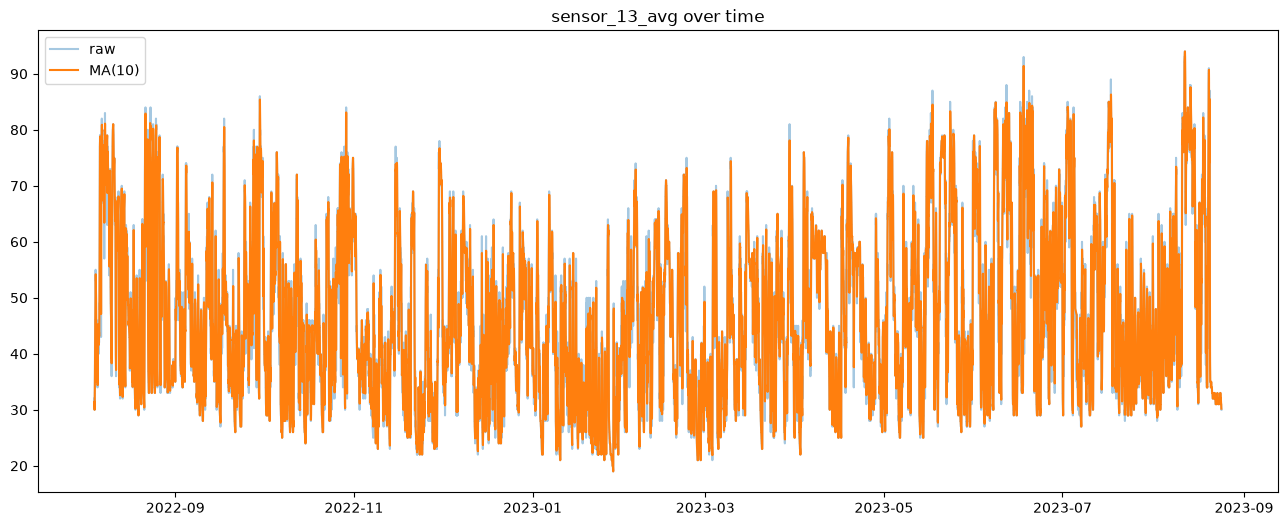

In [ ]:
# 베어링 온도(sensor_13_avg) 평균
plt.figure(figsize=(16, 6))
plt.plot(df.index, df['sensor_13_avg'], alpha=0.4, label='raw')
plt.title('sensor_13_avg over time')
plt.legend()
plt.show()

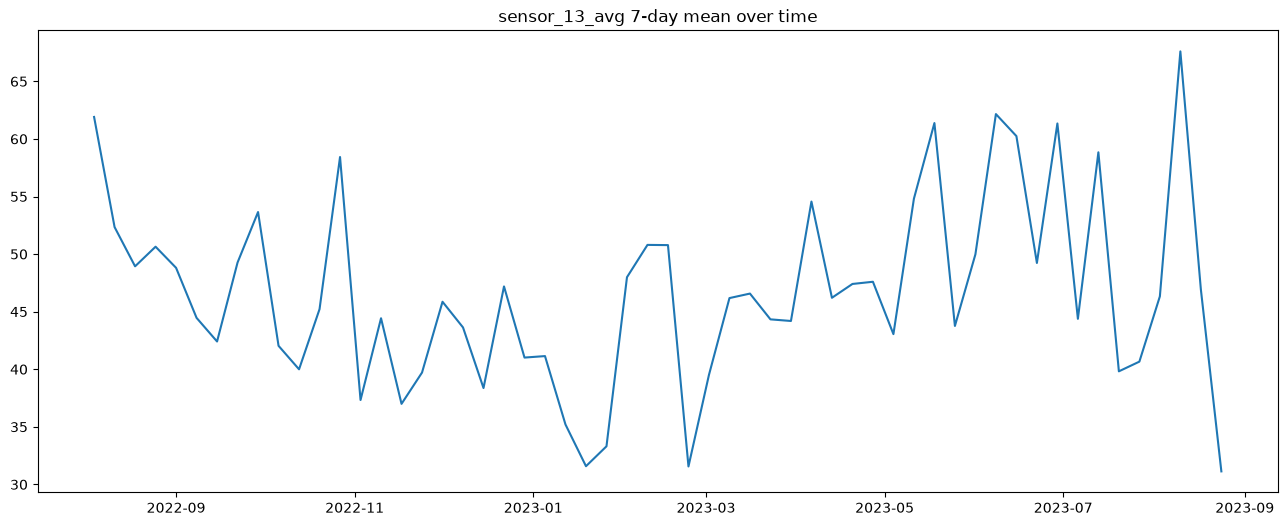

In [70]:
df_13= df['sensor_13_avg'].resample('7D').mean()

plt.figure(figsize=(16, 6))
plt.plot(df_13)
plt.title('sensor_13_avg 7-day mean over time')
plt.show()

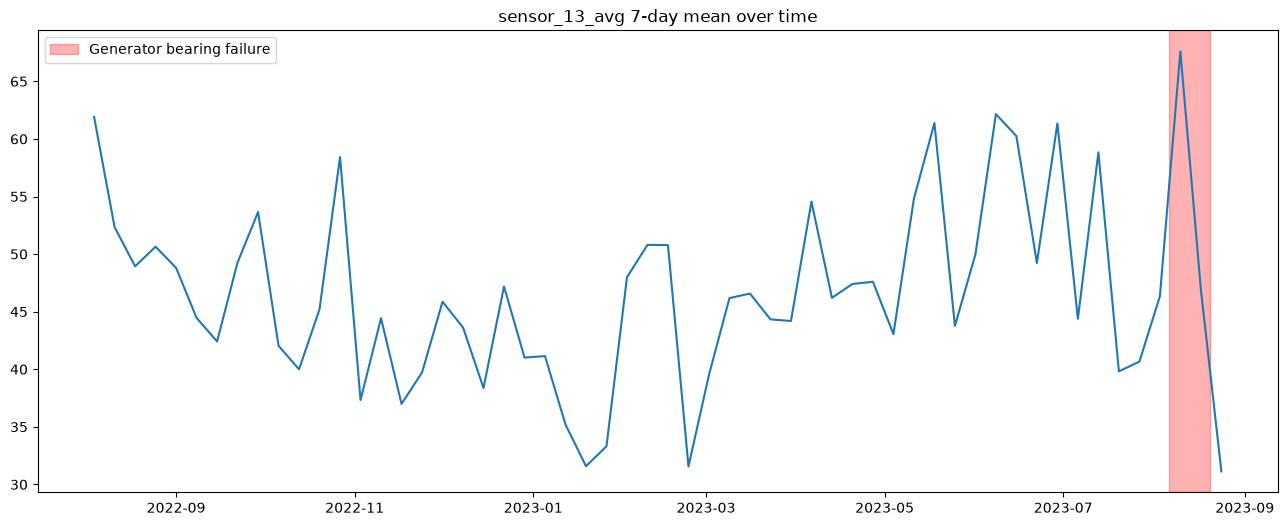

In [74]:
df_13 = df['sensor_13_avg'].resample('7D').mean()

# 0.csv의 고장 구간 (event_info.csv, event_id=0)
fail_start = pd.to_datetime('2023-08-06 06:10:00')
fail_end = pd.to_datetime('2023-08-20 06:10:00')

plt.figure(figsize=(16, 6))
plt.plot(df_13)

# 고장 구간 색칠: alpha는 투명도 (0~1)
plt.axvspan(fail_start, fail_end, color='red', alpha=0.3, label='Generator bearing failure')

plt.title('sensor_13_avg 7-day mean over time')
plt.legend()
plt.show()
